# Homework: Create a 3D Street Art Illusion

Write a Python program using OpenCV to create **anamorphic artwork**: a distorted image that appears correctly proportioned when viewed from a particular position.

Use a laptop, tablet, or monitor as a flat surface representing the pavement. You do not need to paint outdoors.

## Team Size and Submission

Work individually or in a team of **up to three students**. Submit **one Jupyter notebook and one demonstration video per team**.

List all members’ names, student IDs, and contributions in the Jupyter notebook. Include every member’s student ID in the artwork.

## Input and Output

- **Input:** An image showing all team members’ student IDs and a sphere with a three-dimensional appearance, such as a shaded globe.
- **Output:** A distorted artwork image representing a perpendicular view of the display surface. When displayed and observed from your chosen viewpoint, it should appear like the input image.

## Requirements

### 1. Prepare Your Input Image

Include all team members’ student IDs and a shaded or textured sphere. Make the IDs clearly readable.

You may create the sphere yourself or use an existing image, such as `earth.png`. Cite any external image sources.

### 2. Record the Display Geometry

Display a rectangle with clearly marked corners. Define its artwork coordinate system using a canvas of width $W$ and height $H$, with corners:

$$
(0,0),\quad (W-1,0),\quad (W-1,H-1),\quad (0,H-1).
$$

Photograph the rectangle from a **fixed oblique viewpoint**, with all four corners visible. Select their coordinates in the photograph and match them to the corresponding canvas corners. Label the pairs consistently.

### 3. Define the Desired Appearance

On a blank canvas with the **same dimensions as the photograph**, place your input image inside an upright rectangle.

Preserve the input image’s aspect ratio and keep this rectangle entirely inside the photographed display area. This canvas represents what you want the camera to see.

### 4. Generate the Distorted Artwork

Compute a homography $H_{\mathrm{photo}\rightarrow\mathrm{artwork}}$ using the four corner correspondences. (cv2.getPerspectiveTransform)

Apply it to the desired-appearance canvas to generate a $W \times H$ artwork image. State the mapping direction and explain your choice of output dimensions. (cv2.warpPerspective)

### 5. Simulate the Chosen Viewpoint

Warp the artwork back into the photograph’s coordinate system using the inverse homography.

Compare the simulated view with your desired appearance. Discuss any clipping, blur, or interpolation artifacts.

### 6. Verify the Result Physically

Display the artwork in **exactly the same rectangle** used for calibration. Keep the display’s position, orientation, and displayed image size unchanged.

Photograph or record it from the original camera position and orientation, using the same zoom setting. Then observe it from a different viewpoint.

- **Original viewpoint:** The student IDs should be readable, and the sphere should have approximately the intended proportions.
- **Different viewpoint:** The distortion should become apparent.

## Submission

### 1. Jupyter Notebook

Submit one `.ipynb` file with **executed cells and visible outputs**, containing:

- All team members’ names, student IDs, and contributions.
- Your Python code and input image.
- The calibration photograph with labeled corner correspondences.
- The corner coordinates, canvas dimensions, and computed homography.
- The desired-appearance canvas, distorted artwork, and simulated view.
- A photograph of the displayed result from the original viewpoint.
- A brief explanation of your method, results, and remaining errors.
- An **AI-use statement** listing the tools and all assignment-related prompts your team used. AI responses are not required. Explain what you changed in AI-generated code or suggestions and why. If your team did not use AI, state this explicitly.

Include any supporting files needed to run the notebook, and use **relative file paths**.

### 2. Demonstration Video

Submit one video **shorter than one minute**, showing:

- The result from the original viewpoint.
- A continuous movement to a different viewpoint, revealing the distortion.

Keep the artwork and display fixed during the demonstration.

## Display Setup and Example

This assignment requires only **one flat display**, such as a laptop screen, tablet, or monitor, to represent the pavement surface.

The following example demonstration uses **two monitors arranged in an L-shape**. This is an optional extension; your team only needs to demonstrate the effect on a single display.

[Watch the example demonstration](https://youtu.be/3sMitQfzmf8)

concept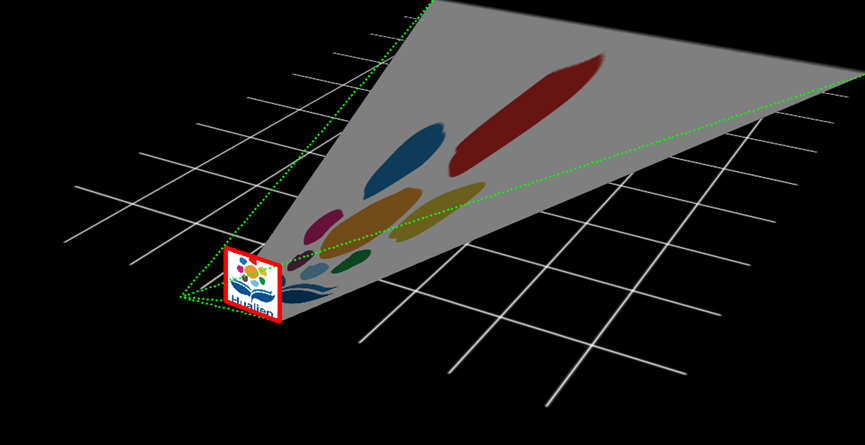

input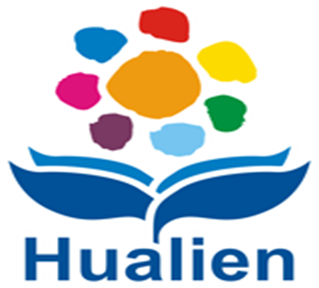

output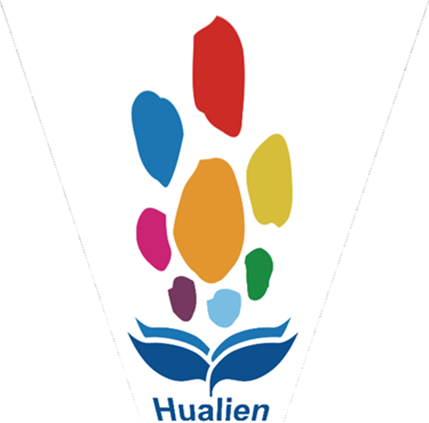

你現在要做的事
## 1. 準備你們的正常目標圖
就是剛剛那張ball.png

## 2. 用你剛剛的四個點，產生扭曲圖
下面這段可以直接跑：

```py
import cv2
import numpy as np
import matplotlib.pyplot as plt

W = 1200
H = 900

art = cv2.imread('ball.png')
art = cv2.cvtColor(art, cv2.COLOR_BGR2RGB)
art = cv2.resize(art, (W, H))

photo_points = np.float32([
    [324, 192],
    [1192, 193],
    [100, 783],
    [1380, 789]
])

normal_points = np.float32([
    [0, 0],
    [W-1, 0],
    [0, H-1],
    [W-1, H-1]
])

xmin = np.min(photo_points[:, 0])
xmax = np.max(photo_points[:, 0])
ymin = np.min(photo_points[:, 1])
ymax = np.max(photo_points[:, 1])

photo_local = np.float32([
    [(324 - xmin) / (xmax - xmin) * (W-1), (192 - ymin) / (ymax - ymin) * (H-1)],
    [(1192 - xmin) / (xmax - xmin) * (W-1), (193 - ymin) / (ymax - ymin) * (H-1)],
    [(100 - xmin) / (xmax - xmin) * (W-1), (783 - ymin) / (ymax - ymin) * (H-1)],
    [(1380 - xmin) / (xmax - xmin) * (W-1), (789 - ymin) / (ymax - ymin) * (H-1)]
])

H_pre = cv2.getPerspectiveTransform(normal_points, photo_local)
distorted = cv2.warpPerspective(art, H_pre, (W, H))

H_rectify = cv2.getPerspectiveTransform(photo_local, normal_points)
simulated = cv2.warpPerspective(distorted, H_rectify, (W, H))

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(art)
plt.title('Desired appearance')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(distorted)
plt.title('Distorted artwork')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(simulated)
plt.title('Simulated view')
plt.axis('off')

plt.show()

distorted_bgr = cv2.cvtColor(distorted, cv2.COLOR_RGB2BGR)
cv2.imwrite('distorted_artwork.png', distorted_bgr)
```

這三張圖各代表什麼
1. Desired appearance
正確角度正常畫面
2. Distorted artwork
正確角度歪斜畫面
3. Simulated view
模擬歪斜角度歪斜畫面

## 3. 接下來實體要做什麼
跑出 distorted_artwork.png 後：
1. 把它顯示在同一個 1200×900 的位置
2. 螢幕位置不要動
3. 相機回到你剛剛拍第二張斜拍照的那個位置
4. 再拍一次
如果成功，你拍到的照片裡會看到：
- 籃球接近正常比例
- 三個學號清楚可讀
- 換角度看會變形
## 4. 你們 Notebook 最後要放的內容
你們最後 .ipynb 建議放這些段落：
(1) 組員資訊
- 411221249
- 411221270
- 411221226
(2) Input image
放正常籃球圖
(3) Calibration photo
放你斜拍白框那張
(4) Corner points
列出這四個點：
photo_points = np.float32([    [324, 192],    [1192, 193],    [100, 783],    [1380, 789]])


(5) Homography
- 還原測試
- distorted artwork
- simulated view
(6) Real result
放實際顯示 distorted_artwork.png 之後，再從指定位置拍的照片
(7) AI usage statement
可以寫：
The basketball image was generated with ChatGPT.
The notebook code was developed with the assistance of ChatGPT and then revised by the team.

## 5. 你現在最該做的事
先做這三步：
1. 把籃球圖存成 ball.png
2. 跑上面的程式
3. 看 simulated view 有沒有接近原圖
如果你願意，我下一步可以直接幫你做兩件事之一：
1. 幫你整理成一份可以直接交的 Notebook 流程
2. 幫你寫一個全螢幕顯示 distorted_artwork.png 的程式
   讓你們可以直接拿去拍最終成果照。

In [ ]:
# Colab 版本：從 GitHub 載入檔案並重新選取四個角點
import os
import subprocess
from pathlib import Path

try:
    from google.colab import _message
    running_in_colab = True
except ImportError:
    running_in_colab = False

if running_in_colab:
    repo_url = 'https://github.com/seanhsu0122/cv1.git'
    repo_dir = Path('/content/cv1')
    if (repo_dir / '.git').is_dir():
        subprocess.run(['git', '-C', str(repo_dir), 'pull', '--ff-only'], check=True)
    else:
        subprocess.run(['git', 'clone', repo_url, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    print(f'已從 GitHub 載入：{repo_dir}')
else:
    repo_dir = Path.cwd()
    print(f'目前使用本機資料夾：{repo_dir}')

import cv2
import matplotlib.pyplot as plt
import numpy as np

image_path = Path('7d3ca7bc-ea64-4112-a766-8553f5957b30.webp')
art_path = Path('ball.png')

if not image_path.exists():
    raise FileNotFoundError(f'找不到 {image_path}')
if not art_path.exists():
    raise FileNotFoundError('找不到 ball.png')

img = cv2.imread(str(image_path))
if img is None:
    raise ValueError(f'OpenCV 無法讀取 {image_path}')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

%pip -q install ipympl
%matplotlib widget

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img_rgb)
ax.set_title('請依序點選 P3(左上)、P1(右上)、P4(左下)、P2(右下)')
ax.axis('on')
plt.show()

clicked_points = plt.ginput(4, timeout=-1)
plt.close(fig)

if len(clicked_points) != 4:
    raise ValueError('必須依序選取四個角點：P3、P1、P4、P2')

# 依 normal_points 的順序建立：左上、右上、左下、右下
photo_points = np.float32(clicked_points)
print('新的 photo_points（左上、右上、左下、右下）：')
print(photo_points)

H, W = img.shape[:2]
normal_points = np.float32([
    [0, 0],
    [W - 1, 0],
    [0, H - 1],
    [W - 1, H - 1]
])

H_rectify_photo = cv2.getPerspectiveTransform(photo_points, normal_points)
rectified_photo = cv2.warpPerspective(img_rgb, H_rectify_photo, (W, H))

art = cv2.imread(str(art_path))
if art is None:
    raise ValueError(f'OpenCV 無法讀取 {art_path}')
art = cv2.cvtColor(art, cv2.COLOR_BGR2RGB)
art = cv2.resize(art, (W, H))

xmin, xmax = np.min(photo_points[:, 0]), np.max(photo_points[:, 0])
ymin, ymax = np.min(photo_points[:, 1]), np.max(photo_points[:, 1])

photo_local = np.float32([
    [(photo_points[0, 0] - xmin) / (xmax - xmin) * (W - 1), (photo_points[0, 1] - ymin) / (ymax - ymin) * (H - 1)],
    [(photo_points[1, 0] - xmin) / (xmax - xmin) * (W - 1), (photo_points[1, 1] - ymin) / (ymax - ymin) * (H - 1)],
    [(photo_points[2, 0] - xmin) / (xmax - xmin) * (W - 1), (photo_points[2, 1] - ymin) / (ymax - ymin) * (H - 1)],
    [(photo_points[3, 0] - xmin) / (xmax - xmin) * (W - 1), (photo_points[3, 1] - ymin) / (ymax - ymin) * (H - 1)]
])

H_pre = cv2.getPerspectiveTransform(normal_points, photo_local)
distorted = cv2.warpPerspective(art, H_pre, (W, H))

H_rectify = cv2.getPerspectiveTransform(photo_local, normal_points)
simulated = cv2.warpPerspective(distorted, H_rectify, (W, H))

plt.figure(figsize=(20, 5))
for index, (image, title) in enumerate([
    (rectified_photo, 'Rectified calibration photo'),
    (art, 'Desired appearance'),
    (distorted, 'Distorted artwork'),
    (simulated, 'Simulated view')
], start=1):
    plt.subplot(1, 4, index)
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
plt.show()

cv2.imwrite('distorted_artwork.png', cv2.cvtColor(distorted, cv2.COLOR_RGB2BGR))
print('已輸出 distorted_artwork.png')